# Part B — Customer Segments and Lapse Prediction

## Objective

This part focuses on understanding customer purchasing behaviour, identifying meaningful customer segments using RFM analysis and K-Means clustering, and predicting customers who are likely to stop ordering.

## Tasks

1. Build the RFM table.
2. Apply K-Means clustering and evaluate different cluster counts.
3. Profile, name and project customer segments.
4. Define the customer lapse prediction problem.
5. Preprocess data without data leakage.
6. Train, tune and evaluate machine learning models.
7. Perform a class-balance experiment, interpret results and persist the selected model.

### 1. Import Required Libraries

Import the libraries required for data manipulation, numerical calculations, visualisation and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

### 2. Set Project Paths

Define the project root directory and the locations of the cleaned datasets and output files.

In [2]:
PROJECT_ROOT = Path.cwd().parent

CLEAN_DATA = PROJECT_ROOT / "data" / "clean"
OUTPUTS = PROJECT_ROOT / "outputs"

OUTPUTS.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Clean data folder:", CLEAN_DATA)
print("Output folder:", OUTPUTS)

Project root: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot
Clean data folder: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot\data\clean
Output folder: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot\outputs


### 3. Load Cleaned Datasets

Load the customer, order and product datasets generated and validated in Part A. These datasets will be used throughout Part B.

In [3]:
customers = pd.read_csv(CLEAN_DATA / "customers.csv")
orders = pd.read_csv(CLEAN_DATA / "orders.csv")
products = pd.read_csv(CLEAN_DATA / "products.csv")

orders["order_ts"] = pd.to_datetime(orders["order_ts"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Products:", products.shape)

Customers: (1200, 5)
Orders: (12309, 9)
Products: (40, 4)


### 4. Verify Loaded Datasets

Check the required columns, dataset sizes and order statuses before starting customer behaviour analysis.

In [4]:
assert customers["customer_id"].nunique() == 1200
assert orders["order_id"].nunique() == 12309
assert products["product_id"].nunique() == 40

print("Order status counts:")
print(orders["status"].value_counts())

print("\nMissing values in each dataset:")
print("Customers:", customers.isna().sum().sum())
print("Orders:", orders.isna().sum().sum())
print("Products:", products.isna().sum().sum())

print("\nPART B DATASET CHECK PASSED")

Order status counts:
status
completed    11110
cancelled     1199
Name: count, dtype: int64

Missing values in each dataset:
Customers: 0
Orders: 1199
Products: 0

PART B DATASET CHECK PASSED


### Task 1: Build the RFM Table

RFM analysis measures customer purchasing behaviour using Recency, Frequency and Monetary value. Only completed orders are considered.

First, filter the order history to include completed orders only.

In [5]:
completed_orders = orders[
    orders["status"] == "completed"
].copy()

print("Completed orders:", len(completed_orders))
print("Unique customers:", completed_orders["customer_id"].nunique())

Completed orders: 11110
Unique customers: 1175


### Calculate Recency, Frequency and Monetary

Use 2025-10-01 00:00:00 as the snapshot moment.

- Recency: Whole days since the customer's most recent completed order.
- Frequency: Number of distinct completed orders.
- Monetary: Total amount spent on completed orders.

In [6]:
snapshot_date = pd.Timestamp("2025-10-01 00:00:00")

rfm = (
    completed_orders.groupby("customer_id")
    .agg(
        last_order_ts=("order_ts", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_amount", "sum")
    )
    .reset_index()
)

rfm["recency"] = (
    snapshot_date - rfm["last_order_ts"]
).dt.days

rfm = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
]

rfm[["monetary"]] = rfm[["monetary"]].round(2)

display(rfm.head())
print("RFM customers:", len(rfm))

,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00


RFM customers: 1175


### Validate RFM Statistics

Calculate summary statistics for Recency, Frequency and Monetary value and compare them with the assignment reference values.

In [7]:
print("RFM Summary Statistics:")
display(rfm[["recency", "frequency", "monetary"]].describe().round(2))

print("\nReference checks:")
print("Recency median:", rfm["recency"].median())
print("Recency minimum:", rfm["recency"].min())
print("Recency maximum:", rfm["recency"].max())
print("Frequency mean:", round(rfm["frequency"].mean(), 2))
print("Frequency maximum:", rfm["frequency"].max())
print("Monetary mean:", round(rfm["monetary"].mean(), 2))
print("Monetary maximum:", round(rfm["monetary"].max(), 2))

RFM Summary Statistics:


,recency,frequency,monetary
count,1175.00,1175.00,1175.00
mean,33.56,9.46,2552.06
std,38.43,8.01,2367.31
min,0.00,1.00,12.00
25%,6.00,3.00,505.45
50%,19.00,5.00,2286.50
75%,46.00,17.00,3751.52
max,180.00,33.00,14766.55



Reference checks:
Recency median: 19.0
Recency minimum: 0
Recency maximum: 180
Frequency mean: 9.46
Frequency maximum: 33
Monetary mean: 2552.06
Monetary maximum: 14766.55


### Task 2: K-Means Clustering

Standardise the RFM features before applying K-Means. Standardisation ensures that differences in feature scales do not dominate the clustering process.

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Standardise RFM Features

Use StandardScaler to transform Recency, Frequency and Monetary into standardised values. These scaled features will be used for K-Means clustering.

In [9]:
rfm_features = rfm[["recency", "frequency", "monetary"]]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("Scaled RFM shape:", rfm_scaled.shape)
print("\nScaled feature means:", rfm_scaled.mean(axis=0).round(4))
print("Scaled feature standard deviations:", rfm_scaled.std(axis=0).round(4))

Scaled RFM shape: (1175, 3)

Scaled feature means: [-0.  0. -0.]
Scaled feature standard deviations: [1. 1. 1.]


### Evaluate Different Cluster Counts

Fit K-Means for each K from 2 to 8 using n_init=10 and random_state=42.

Record:
- Inertia: measures within-cluster sum of squared distances.
- Silhouette score: measures how well-separated the clusters are.

These metrics will help select an appropriate number of customer segments.

In [10]:
cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(rfm_scaled, labels)

    cluster_results.append({
        "K": k,
        "Inertia": round(inertia, 1),
        "Silhouette": round(silhouette, 3)
    })

cluster_results_df = pd.DataFrame(cluster_results)

display(cluster_results_df)

,K,Inertia,Silhouette
0,2,1820.8,0.465
1,3,1268.2,0.445
2,4,743.1,0.526
3,5,617.4,0.480
4,6,503.2,0.482
5,7,408.5,0.416
6,8,366.5,0.412


### Elbow Method

Plot the inertia values for K=2 to K=8. The elbow point helps identify where increasing the number of clusters produces diminishing improvements.

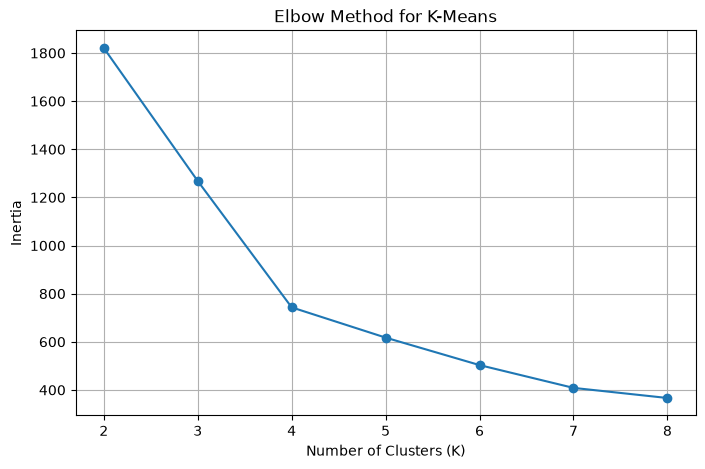

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results_df["K"],
    cluster_results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

### Selecting the Final Number of Clusters

The final number of clusters is selected as K=4. It has the highest silhouette score of 0.526 and a clear improvement in inertia compared with K=3. Although higher values of K reduce inertia further, four segments offer a practical balance between cluster separation and business interpretability.

Inertia always decreases as K increases because adding more clusters allows observations to be closer to their assigned cluster centres. Therefore, the lower inertia at K=8 does not automatically make it the best choice; the elbow, silhouette score and business usefulness must also be considered.

### Fit Final K-Means Model

Train the final K-Means model using four clusters and assign a segment ID to every customer in the RFM table.


In [12]:
final_kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

rfm["segment_id"] = final_kmeans.fit_predict(rfm_scaled)

print("Customer distribution across segments:")
print(rfm["segment_id"].value_counts().sort_index())

Customer distribution across segments:
segment_id
0    436
1    138
2    419
3    182
Name: count, dtype: int64


### Segment Profiling

Calculate the customer count and average Recency, Frequency and Monetary values for each of the four clusters. These profiles will help identify the purchasing behaviour of each segment.

In [13]:
segment_profile = (
    rfm.groupby("segment_id")
    .agg(
        customer_count=("customer_id", "count"),
        mean_recency=("recency", "mean"),
        mean_frequency=("frequency", "mean"),
        mean_monetary=("monetary", "mean")
    )
    .round(2)
)

display(segment_profile)

,customer_count,mean_recency,mean_frequency,mean_monetary
segment_id,,,,
0,436,28.86,3.77,1057.62
1,138,24.12,6.77,7129.70
2,419,8.77,19.40,3410.02
3,182,109.04,2.20,685.99


### Business Segment Names and Recommended Actions

Assign meaningful business names to the clusters based on their RFM profiles. Segment IDs are only machine-generated labels and do not represent a ranking or customer value order.

The segment with the highest mean monetary value is marked as Premium.

In [14]:
segment_names = {
    0: "Regular Low-Value Customers",
    1: "Premium Customers",
    2: "Loyal Active Customers",
    3: "At-Risk Customers"
}

segment_actions = {
    0: "Offer personalised recommendations and encourage repeat purchases.",
    1: "Provide exclusive offers, loyalty rewards and premium benefits.",
    2: "Reward loyalty and encourage continued engagement.",
    3: "Launch win-back campaigns with targeted discounts."
}

premium_segment_id = segment_profile["mean_monetary"].idxmax()

segment_profile["segment_name"] = segment_profile.index.map(segment_names)
segment_profile["recommended_action"] = segment_profile.index.map(segment_actions)
segment_profile["is_premium"] = segment_profile.index == premium_segment_id

display(segment_profile)
print("Premium segment ID:", premium_segment_id)

,customer_count,mean_recency,mean_frequency,mean_monetary,segment_name,recommended_action,is_premium
segment_id,,,,,,,
0,436,28.86,3.77,1057.62,Regular Low-Value Customers,Offer personalised recommendations and encoura...,False
1,138,24.12,6.77,7129.70,Premium Customers,"Provide exclusive offers, loyalty rewards and ...",True
2,419,8.77,19.40,3410.02,Loyal Active Customers,Reward loyalty and encourage continued engagem...,False
3,182,109.04,2.20,685.99,At-Risk Customers,Launch win-back campaigns with targeted discou...,False


Premium segment ID: 1


In [15]:
print(segment_profile.to_string())

            customer_count  mean_recency  mean_frequency  mean_monetary                 segment_name                                                  recommended_action  is_premium
segment_id                                                                                                                                                                          
0                      436         28.86            3.77        1057.62  Regular Low-Value Customers  Offer personalised recommendations and encourage repeat purchases.       False
1                      138         24.12            6.77        7129.70            Premium Customers     Provide exclusive offers, loyalty rewards and premium benefits.        True
2                      419          8.77           19.40        3410.02       Loyal Active Customers                  Reward loyalty and encourage continued engagement.       False
3                      182        109.04            2.20         685.99            At-Risk Cust

Business interpretation:
- Segment 0: Regular Low-Value Customers — encourage repeat purchases.
- Segment 1: Premium Customers — offer exclusive rewards.
- Segment 2: Loyal Active Customers — reward continued engagement.
- Segment 3: At-Risk Customers — launch win-back campaigns.

### Principal Component Analysis (PCA)

Apply PCA with two components to the standardised RFM features. Calculate the explained variance ratio to understand how much of the original information is retained in the two-dimensional representation.

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:", explained_variance.round(3))
print("Total explained variance:", round(explained_variance.sum(), 3))

Explained variance ratio: [0.634 0.218]
Total explained variance: 0.852


### Visualise Customer Segments Using PCA

Plot the four customer segments using the first two principal components. This provides a two-dimensional view of how the customers are distributed across clusters.

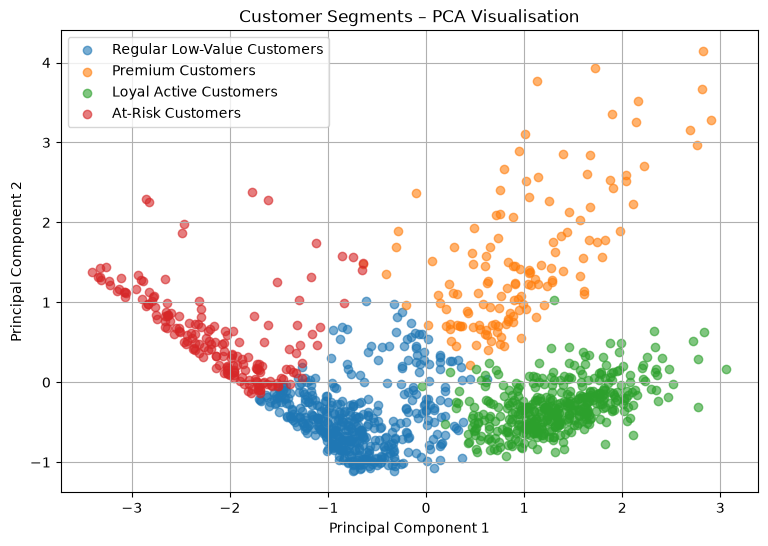

In [17]:
plt.figure(figsize=(9, 6))

for segment_id in sorted(rfm["segment_id"].unique()):
    mask = rfm["segment_id"] == segment_id

    plt.scatter(
        rfm_pca[mask, 0],
        rfm_pca[mask, 1],
        label=segment_names[segment_id],
        alpha=0.6
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments – PCA Visualisation")
plt.legend()
plt.grid(True)
plt.show()

### Export Customer Segment Results

Save the RFM metrics, segment assignments, business names and Premium flag to outputs/customer_segments.csv. This file will also be used by Part C for ticket routing.

In [18]:
customer_segments = rfm.copy()

customer_segments["segment_name"] = (
    customer_segments["segment_id"].map(segment_names)
)

customer_segments["is_premium"] = (
    customer_segments["segment_id"] == premium_segment_id
)

customer_segments = customer_segments[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "segment_id",
        "segment_name",
        "is_premium"
    ]
]

customer_segments.to_csv(
    OUTPUTS / "customer_segments.csv",
    index=False
)

print("Saved:", OUTPUTS / "customer_segments.csv")
print("Rows:", len(customer_segments))
print("\nPremium customers:",
      customer_segments["is_premium"].sum())

display(customer_segments.head())

Saved: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot\outputs\customer_segments.csv
Rows: 1175

Premium customers: 138


,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Regular Low-Value Customers,False
1,C0002,28,7,4644.90,1,Premium Customers,True
2,C0003,7,22,3644.85,2,Loyal Active Customers,False
3,C0004,0,5,369.00,0,Regular Low-Value Customers,False
4,C0005,147,2,324.00,3,At-Risk Customers,False


### Final Customer Segment Summary

Summarise the four customer segments, including their customer counts, average RFM values, business names, recommended actions and Premium classification.

In [19]:
final_segment_summary = segment_profile[
    [
        "customer_count",
        "mean_recency",
        "mean_frequency",
        "mean_monetary",
        "segment_name",
        "recommended_action",
        "is_premium"
    ]
].copy()

display(final_segment_summary)

,customer_count,mean_recency,mean_frequency,mean_monetary,segment_name,recommended_action,is_premium
segment_id,,,,,,,
0,436,28.86,3.77,1057.62,Regular Low-Value Customers,Offer personalised recommendations and encoura...,False
1,138,24.12,6.77,7129.70,Premium Customers,"Provide exclusive offers, loyalty rewards and ...",True
2,419,8.77,19.40,3410.02,Loyal Active Customers,Reward loyalty and encourage continued engagem...,False
3,182,109.04,2.20,685.99,At-Risk Customers,Launch win-back campaigns with targeted discou...,False


### Lapse Prediction — Cutoff and Label Window

Use September 1, 2025 as the cutoff. Orders before this date form the feature history. Completed orders during September determine whether a customer lapsed.

In [20]:
cutoff_date = pd.Timestamp("2025-09-01 00:00:00")
label_end_date = pd.Timestamp("2025-10-01 00:00:00")

# Only completed orders before the cutoff are used for customer features.
pre_cutoff_completed = completed_orders[
    completed_orders["order_ts"] < cutoff_date
].copy()

# Customers with at least one completed order before the cutoff.
cohort_ids = pre_cutoff_completed["customer_id"].unique()

print("Pre-cutoff completed orders:", len(pre_cutoff_completed))
print("Lapse prediction cohort:", len(cohort_ids))

Pre-cutoff completed orders: 9281
Lapse prediction cohort: 1156


### Create the Lapse Target

A customer is labelled as lapsed (1) if they have no completed orders during September 2025. Otherwise, they are labelled as not lapsed (0). September orders are used only for the target label, not as model features.

In [21]:
september_completed = completed_orders[
    (completed_orders["order_ts"] >= cutoff_date) &
    (completed_orders["order_ts"] < label_end_date)
]

september_active_ids = set(september_completed["customer_id"])

lapse_labels = pd.DataFrame({"customer_id": cohort_ids})
lapse_labels["lapsed"] = (
    ~lapse_labels["customer_id"].isin(september_active_ids)
).astype(int)

print("Cohort customers:", len(lapse_labels))
print("\nLapse label counts:")
print(lapse_labels["lapsed"].value_counts().sort_index())

print("\nLapsed percentage:",
      round(lapse_labels["lapsed"].mean() * 100, 2), "%")

Cohort customers: 1156

Lapse label counts:
lapsed
0    713
1    443
Name: count, dtype: int64

Lapsed percentage: 38.32 %


we'll calculate customer behaviour using only completed orders before September 1. We'll also use all pre-cutoff orders with a final status to calculate cancellation rate.

In [22]:
# All final-status orders before the cutoff, for cancellation rate.
pre_cutoff_all = orders[
    (orders["order_ts"] < cutoff_date) &
    (orders["status"].isin(["completed", "cancelled"]))
].copy()

# Add product category to completed orders.
pre_cutoff_with_category = pre_cutoff_completed.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Completed-order behaviour.
feature_history = (
    pre_cutoff_with_category.groupby("customer_id")
    .agg(
        last_order_ts=("order_ts", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_amount", "sum"),
        avg_discount_pct=("discount_pct", "mean"),
        avg_delivery_minutes=("delivery_minutes", "mean")
    )
    .reset_index()
)

# Cancellation rate = cancelled orders / all final-status orders.
status_counts = (
    pre_cutoff_all.groupby(["customer_id", "status"])
    .size()
    .unstack(fill_value=0)
)

for status in ["completed", "cancelled"]:
    if status not in status_counts.columns:
        status_counts[status] = 0

status_counts["cancellation_rate"] = (
    status_counts["cancelled"] /
    (status_counts["completed"] + status_counts["cancelled"])
)

feature_history = feature_history.merge(
    status_counts[["cancellation_rate"]],
    on="customer_id",
    how="left"
)

# Most frequently purchased product category before the cutoff.
favourite_category = (
    pre_cutoff_with_category.groupby("customer_id")["category"]
    .agg(lambda values: values.value_counts().index[0])
    .rename("favourite_category")
    .reset_index()
)

feature_history = feature_history.merge(
    favourite_category,
    on="customer_id",
    how="left"
)

# Recency is measured from the cutoff date.
feature_history["recency"] = (
    cutoff_date - feature_history["last_order_ts"]
).dt.days

feature_history = feature_history.drop(columns="last_order_ts")

print("Customers with feature history:", len(feature_history))
display(feature_history.head())

Customers with feature history: 1156


,customer_id,frequency,monetary,avg_discount_pct,avg_delivery_minutes,cancellation_rate,favourite_category,recency
0,C0001,2,378.00,10.000000,28.000000,0.000000,Grocery,33
1,C0002,6,3946.90,6.666667,21.916667,0.000000,Electronics,22
2,C0003,20,3264.05,12.750000,24.200000,0.000000,Grocery,1
3,C0004,3,272.25,11.666667,35.666667,0.400000,Snacks,42
4,C0005,2,324.00,25.000000,26.000000,0.333333,Dairy,117


### Add Customer Profile Information

Combine the pre-cutoff purchase behaviour with customer demographics. Calculate customer tenure using the cutoff date, not the current date.

In [23]:
customer_features = customers[
    ["customer_id", "city", "age", "gender", "signup_date"]
].copy()

customer_features["tenure_days"] = (
    cutoff_date - customer_features["signup_date"]
).dt.days

customer_features = customer_features.drop(columns="signup_date")

# Combine purchase behaviour and customer profile.
X_all = feature_history.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Attach the target label separately.
lapse_dataset = X_all.merge(
    lapse_labels,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

print("Dataset shape:", lapse_dataset.shape)
print("\nMissing values:")
print(lapse_dataset.isnull().sum())

display(lapse_dataset.head())

Dataset shape: (1156, 13)

Missing values:
customer_id             0
frequency               0
monetary                0
avg_discount_pct        0
avg_delivery_minutes    0
cancellation_rate       0
favourite_category      0
recency                 0
city                    0
age                     0
gender                  0
tenure_days             0
lapsed                  0
dtype: int64


,customer_id,frequency,monetary,avg_discount_pct,avg_delivery_minutes,cancellation_rate,favourite_category,recency,city,age,gender,tenure_days,lapsed
0,C0001,2,378.00,10.000000,28.000000,0.000000,Grocery,33,Chennai,35.0,male,597,0
1,C0002,6,3946.90,6.666667,21.916667,0.000000,Electronics,22,Delhi,31.0,male,562,0
2,C0003,20,3264.05,12.750000,24.200000,0.000000,Grocery,1,Bengaluru,18.0,female,195,0
3,C0004,3,272.25,11.666667,35.666667,0.400000,Snacks,42,Bengaluru,24.0,female,437,0
4,C0005,2,324.00,25.000000,26.000000,0.333333,Dairy,117,Bengaluru,25.0,female,335,1


### Separate Model Features and Target

Keep customer_id only for tracking customers and lapsed as the prediction target. Exclude both from the model features to prevent identifier or target leakage.

In [24]:
# Target variable.
y = lapse_dataset["lapsed"].copy()

# Model features: exclude customer_id and lapsed.
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount_pct",
    "cancellation_rate",
    "avg_delivery_minutes",
    "favourite_category",
    "city",
    "age",
    "gender",
    "tenure_days"
]

X = lapse_dataset[feature_columns].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nFeature columns:")
print(X.columns.tolist())

assert "customer_id" not in X.columns
assert "lapsed" not in X.columns
assert not any("segment" in col.lower() for col in X.columns)
assert X.isnull().sum().sum() == 0

print("\nFEATURE AND TARGET CHECK PASSED")

Feature shape: (1156, 11)
Target shape: (1156,)

Target distribution:
lapsed
0    713
1    443
Name: count, dtype: int64

Feature columns:
['recency', 'frequency', 'monetary', 'avg_discount_pct', 'cancellation_rate', 'avg_delivery_minutes', 'favourite_category', 'city', 'age', 'gender', 'tenure_days']

FEATURE AND TARGET CHECK PASSED


### Stratified Train-Test Split

Split the dataset into 80% training and 20% testing. Stratification preserves the target-class proportions. The test set will remain untouched during model training and tuning.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (924, 11)
Testing features: (232, 11)

Training target distribution:
lapsed
0    570
1    354
Name: count, dtype: int64

Testing target distribution:
lapsed
0    143
1     89
Name: count, dtype: int64


### Define Preprocessing Columns

Numeric features are standardised using StandardScaler. Categorical features (city, gender and favourite product category) are converted into one-hot encoded columns using drop="first", which removes one reference category from each feature.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount_pct",
    "cancellation_rate",
    "avg_delivery_minutes",
    "age",
    "tenure_days"
]

categorical_features = [
    "city",
    "gender",
    "favourite_category"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
         categorical_features)
    ]
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numeric_features) + len(categorical_features))

Numeric features: 8
Categorical features: 3
Total input features: 11


### Baseline Model — Majority Class

Use DummyClassifier to predict the majority training class for every test customer. Measure accuracy and lapsed-class precision, recall and F1-score.

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Accuracy:", round(accuracy_score(y_test, baseline_predictions), 3))
print("Lapsed Precision:", round(precision_score(y_test, baseline_predictions, zero_division=0), 3))
print("Lapsed Recall:", round(recall_score(y_test, baseline_predictions, zero_division=0), 3))
print("Lapsed F1:", round(f1_score(y_test, baseline_predictions, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.616
Lapsed Precision: 0.0
Lapsed Recall: 0.0
Lapsed F1: 0.0

Confusion Matrix:
[[143   0]
 [ 89   0]]


### Logistic Regression — Hyperparameter Tuning

Build a pipeline containing the preprocessing steps and LogisticRegression. Use GridSearchCV with 5-fold cross-validation and F1-score to select the best regularisation strength (C). All preprocessing is fitted within each training fold.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_params = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

best_logistic_model = logistic_search.best_estimator_

print("Best Logistic Regression parameters:")
print(logistic_search.best_params_)

print("\nBest Logistic Regression CV F1:")
print(round(logistic_search.best_score_, 3))

Best Logistic Regression parameters:
{'model__C': 10}

Best Logistic Regression CV F1:
0.656


### Random Forest — Hyperparameter Tuning

Train a RandomForestClassifier using a pipeline with the same preprocessing. Use GridSearchCV to test three max_depth values and three min_samples_leaf values. Select the best combination using 5-fold cross-validation and F1-score.

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_params = {
    "model__max_depth": [3, 5, 8],
    "model__min_samples_leaf": [5, 10, 20]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

best_rf_model = rf_search.best_estimator_

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest Random Forest CV F1:")
print(round(rf_search.best_score_, 3))

Best Random Forest parameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 5}

Best Random Forest CV F1:
0.685


### Test Set Evaluation

Evaluate the tuned Logistic Regression and Random Forest models on the untouched test set. Compare accuracy, precision, recall and F1 for the lapsed class, along with their confusion matrices.

In [30]:
models = {
    "Logistic Regression": best_logistic_model,
    "Random Forest": best_rf_model
}

evaluation_results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(precision_score(y_test, predictions, zero_division=0), 3),
        "Recall": round(recall_score(y_test, predictions, zero_division=0), 3),
        "F1": round(f1_score(y_test, predictions, zero_division=0), 3)
    })

    print(f"\n{model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

evaluation_df = pd.DataFrame(evaluation_results)

print("\nModel Comparison:")
display(evaluation_df)


Logistic Regression
Confusion Matrix:
[[104  39]
 [ 32  57]]

Random Forest
Confusion Matrix:
[[107  36]
 [ 32  57]]

Model Comparison:


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.694,0.594,0.64,0.616
1,Random Forest,0.707,0.613,0.64,0.626


### Oversampling — Balance Training Classes

Retain all original training rows and randomly duplicate lapsed customers with replacement until both classes have equal counts. Use random_state=42 for reproducibility. Do not oversample the test set.

In [31]:
# Keep all original training rows and their labels.
original_training = X_train.copy()
original_training["lapsed"] = y_train.to_numpy()

# Select additional lapsed customers with replacement.
X_minority_extra = X_minority.sample(
    n=len(X_majority) - len(X_minority),
    replace=True,
    random_state=42
)

# All duplicated customers belong to class 1.
extra_training = X_minority_extra.copy()
extra_training["lapsed"] = 1

# Combine and shuffle features and labels together.
balanced_training = pd.concat(
    [original_training, extra_training],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Separate balanced features and target.
X_train_balanced = balanced_training.drop(columns="lapsed")
y_train_balanced = balanced_training["lapsed"]

print("Balanced training shape:", X_train_balanced.shape)
print("\nBalanced target distribution:")
print(y_train_balanced.value_counts().sort_index())

assert len(X_train_balanced) == len(y_train_balanced) == 1140
assert y_train_balanced.value_counts().to_dict() == {0: 570, 1: 570}

print("\nOVERSAMPLING CHECK PASSED")

NameError: name 'X_minority' is not defined

### Logistic Regression — Balanced Training

Refit the best Logistic Regression pipeline using the balanced training dataset. Evaluate its predictions on the original, unchanged test set.

In [ ]:
from sklearn.base import clone

balanced_logistic_model = clone(best_logistic_model)

balanced_logistic_model.fit(
    X_train_balanced,
    y_train_balanced
)

balanced_predictions = balanced_logistic_model.predict(X_test)

balanced_precision = precision_score(
    y_test, balanced_predictions, zero_division=0
)
balanced_recall = recall_score(
    y_test, balanced_predictions, zero_division=0
)
balanced_f1 = f1_score(
    y_test, balanced_predictions, zero_division=0
)

print("Balanced Logistic Regression")
print("Precision:", round(balanced_precision, 3))
print("Recall:", round(balanced_recall, 3))
print("F1:", round(balanced_f1, 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_predictions))

Balanced Logistic Regression
Precision: 0.595
Recall: 0.876
F1: 0.709

Confusion Matrix:
[[90 53]
 [11 78]]


Interpretation:
- Recall increased from 64.0% to 87.6%. The model now identifies 78 of the 89 lapsed customers instead of 57.
- Precision remained almost unchanged (59.4% to 59.5%).
- The biggest improvement is recall, meaning fewer genuinely lapsed customers are missed.
- The trade-off is more false alarms: 53 loyal customers are now incorrectly flagged, compared with 39 before.

### Training-Only Scaler Verification

Compare the frequency mean learned by the fitted Logistic Regression preprocessing pipeline with the full cohort frequency mean. The scaler should learn its mean from training data only, not from the test set.

In [ ]:
# Get the fitted numeric scaler from the tuned Logistic Regression pipeline.
fitted_scaler = (
    best_logistic_model
    .named_steps["preprocessor"]
    .named_transformers_["num"]
)

frequency_index = numeric_features.index("frequency")

training_frequency_mean = fitted_scaler.mean_[frequency_index]
full_cohort_frequency_mean = X["frequency"].mean()

print("Training-only scaler frequency mean:",
      round(training_frequency_mean, 2))

print("Full cohort frequency mean:",
      round(full_cohort_frequency_mean, 2))

print("\nScaler fitted using training data only:",
      len(X_train), "customers")

Training-only scaler frequency mean: 8.11
Full cohort frequency mean: 8.03

Scaler fitted using training data only: 924 customers


### Random Forest — Top Five Important Features

Extract feature names after preprocessing and rank them using the fitted Random Forest feature importances. These values indicate how much each feature contributes to the model's decisions.

In [ ]:
rf_preprocessor = best_rf_model.named_steps["preprocessor"]
rf_classifier = best_rf_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

print("Top 5 Random Forest Features:")
display(rf_importance.head(5))

Top 5 Random Forest Features:


,feature,importance
0,num__frequency,0.256631
1,num__monetary,0.254441
2,num__recency,0.116121
3,num__avg_delivery_minutes,0.068503
4,num__avg_discount_pct,0.059748


Business interpretation:
1. Frequency: Purchase frequency is the strongest predictor. Customers who purchase regularly may be less likely to lapse.
2. Monetary: Total spending is almost equally important. Customer spending history helps distinguish valuable customer groups.
3. Recency: How recently a customer purchased is another important signal. Longer gaps may indicate a lapse risk.
4. Average delivery minutes: Delivery experience may influence whether customers continue purchasing.
5. Average discount percentage: Discount usage helps identify customers whose purchasing behaviour may be influenced by promotions.
These are predictive importance scores, not proof that any feature causes customers to lapse.

### Logistic Regression — Top Three Coefficients

Extract the three coefficients with the largest absolute values from the balanced Logistic Regression model. Positive coefficients indicate higher predicted lapse odds; negative coefficients indicate lower predicted lapse odds, holding other features constant.

In [ ]:
balanced_preprocessor = (
    balanced_logistic_model.named_steps["preprocessor"]
)

balanced_classifier = (
    balanced_logistic_model.named_steps["model"]
)

logistic_feature_names = balanced_preprocessor.get_feature_names_out()

logistic_coefficients = pd.DataFrame({
    "feature": logistic_feature_names,
    "coefficient": balanced_classifier.coef_[0]
})

logistic_coefficients["absolute_coefficient"] = (
    logistic_coefficients["coefficient"].abs()
)

top_logistic_coefficients = (
    logistic_coefficients
    .sort_values("absolute_coefficient", ascending=False)
    .head(3)
    .drop(columns="absolute_coefficient")
    .reset_index(drop=True)
)

display(top_logistic_coefficients)

,feature,coefficient
0,num__frequency,-1.374986
1,cat__favourite_category_Electronics,-0.527404
2,cat__city_Delhi,-0.455277


### Save and Verify the Final Lapse Model

Save the balanced Logistic Regression pipeline, including its fitted preprocessing steps. Reload it and compare its test predictions with the original model predictions.

In [ ]:
import joblib

model_path = OUTPUTS / "lapse_model.joblib"

# Save the complete fitted pipeline.
joblib.dump(balanced_logistic_model, model_path)

# Reload the saved model.
loaded_model = joblib.load(model_path)

# Verify predictions are identical.
original_predictions = balanced_logistic_model.predict(X_test)
reloaded_predictions = loaded_model.predict(X_test)

assert np.array_equal(original_predictions, reloaded_predictions)

print("Model saved:", model_path)
print("Test predictions identical:",
      np.array_equal(original_predictions, reloaded_predictions))
print("MODEL SAVE AND RELOAD CHECK PASSED")

Model saved: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot\outputs\lapse_model.joblib
Test predictions identical: True
MODEL SAVE AND RELOAD CHECK PASSED


### Premium Customer Retention List

Predict lapse probabilities for test customers using the saved model. Filter to Premium customers, rank them by predicted lapse probability and save the top 10 for retention outreach. This list is illustrative because Premium status uses the full RFM window.

In [ ]:
# Predict lapse probabilities for the unchanged test set.
lapse_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Recover the customer IDs corresponding to the test rows.
test_results = pd.DataFrame({
    "customer_id": lapse_dataset.loc[X_test.index, "customer_id"].to_numpy(),
    "lapse_probability": lapse_probabilities,
    "actually_lapsed": y_test.to_numpy()
})

# Load the saved customer segments and identify Premium customers.
saved_segments = pd.read_csv(OUTPUTS / "customer_segments.csv")

premium_ids = saved_segments.loc[
    saved_segments["is_premium"].astype(str).str.lower().isin(["true", "1"]),
    "customer_id"
]

# Keep Premium customers and rank by predicted lapse probability.
retention_list = (
    test_results[test_results["customer_id"].isin(premium_ids)]
    .sort_values("lapse_probability", ascending=False)
    .head(10)
    .copy()
)

retention_list["lapse_probability"] = (
    retention_list["lapse_probability"].round(4)
)

retention_list = retention_list[
    ["customer_id", "lapse_probability", "actually_lapsed"]
]

# Save the retention list.
retention_path = OUTPUTS / "retention_list.csv"
retention_list.to_csv(retention_path, index=False)

print("Retention list saved:", retention_path)
print("Premium customers in test set:", len(test_results[
    test_results["customer_id"].isin(premium_ids)
]))
print("Customers in retention list:", len(retention_list))
print("Actually lapsed in top 10:",
      int(retention_list["actually_lapsed"].sum()))

display(retention_list)

Retention list saved: d:\Capstone Project\Intelligence & Support Copilot — Capstone Project\Intelligence & Support Copilot\outputs\retention_list.csv
Premium customers in test set: 40
Customers in retention list: 10
Actually lapsed in top 10: 2


,customer_id,lapse_probability,actually_lapsed
227,C0060,0.8031,0
84,C0831,0.6869,0
57,C0082,0.6749,0
180,C0271,0.6710,1
190,C0267,0.6623,0
210,C0021,0.6515,0
216,C0942,0.6415,0
58,C0525,0.5996,1
153,C1156,0.5866,0
27,C1112,0.5756,0


Business interpretation: These 10 customers are the highest-priority Premium customers according to the model's predicted lapse probabilities. Two were actually labelled as lapsed in September. The remaining eight were not lapsed, so the list can be used as a proactive retention outreach shortlist rather than a confirmed list of lost customers.

### Part B — Results and Model Selection

The baseline achieved 61.6% accuracy but an F1-score of 0.000 for lapsed customers because it predicted every customer as not lapsed.

The tuned Logistic Regression achieved a test F1 of 0.616. The tuned Random Forest achieved a test F1 of 0.626. After oversampling only the training data, Logistic Regression achieved precision 0.595, recall 0.876 and F1 0.709 on the original test set.

The balanced Logistic Regression model was selected because identifying more genuinely lapsed customers is important for retention campaigns. Its higher recall reduces missed lapse cases, although it also produces more false positives and may lead to unnecessary outreach.

The top five Random Forest features were frequency, monetary, recency, average delivery minutes and average discount percentage. The three strongest balanced Logistic Regression coefficients were frequency (-1.3750), favourite category Electronics (-0.5274) and city Delhi (-0.4553).

The Premium retention list contains the 10 highest predicted lapse probabilities among Premium customers in the test set. Two of these 10 customers were actually lapsed. This list is illustrative because Premium status is based on the full RFM window, including September activity.

### Part B — Output File Validation

Verify that all required Part B output files exist and that the customer segment and retention list files contain the expected columns and row counts.

In [ ]:
required_files = [
    OUTPUTS / "customer_segments.csv",
    OUTPUTS / "lapse_model.joblib",
    OUTPUTS / "retention_list.csv"
]

for file_path in required_files:
    print(file_path.name, ":", "EXISTS" if file_path.exists() else "MISSING")

saved_customer_segments = pd.read_csv(
    OUTPUTS / "customer_segments.csv"
)

saved_retention_list = pd.read_csv(
    OUTPUTS / "retention_list.csv"
)

print("\nCustomer segments shape:", saved_customer_segments.shape)
print("Customer segment columns:", saved_customer_segments.columns.tolist())

print("\nRetention list shape:", saved_retention_list.shape)
print("Retention list columns:", saved_retention_list.columns.tolist())

assert all(file_path.exists() for file_path in required_files)
assert len(saved_customer_segments) == 1175
assert saved_customer_segments.columns.tolist() == [
    "customer_id", "recency", "frequency", "monetary",
    "segment_id", "segment_name", "is_premium"
]
assert saved_retention_list.columns.tolist() == [
    "customer_id", "lapse_probability", "actually_lapsed"
]
assert len(saved_retention_list) <= 10

print("\nPART B OUTPUT VALIDATION PASSED")

customer_segments.csv : EXISTS
lapse_model.joblib : EXISTS
retention_list.csv : EXISTS

Customer segments shape: (1175, 7)
Customer segment columns: ['customer_id', 'recency', 'frequency', 'monetary', 'segment_id', 'segment_name', 'is_premium']

Retention list shape: (10, 3)
Retention list columns: ['customer_id', 'lapse_probability', 'actually_lapsed']

PART B OUTPUT VALIDATION PASSED
